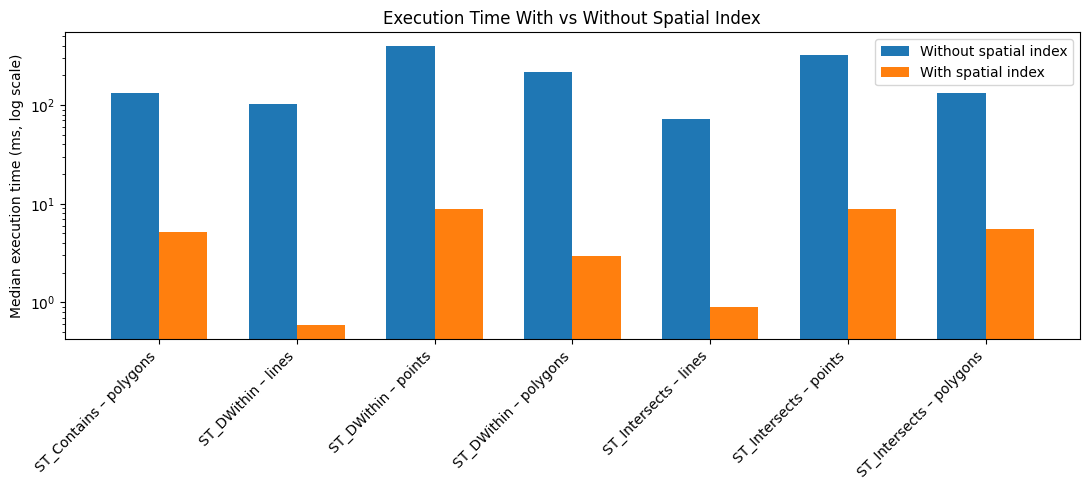

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load results
df_no = pd.read_csv("baseline_spatial_ops_no_index.csv")
df_ix = pd.read_csv("baseline_spatial_ops_with_index.csv")

# Aggregate: median over reference points
agg_no = (
    df_no
    .groupby(["operation", "geometry_type"])["median_ms"]
    .median()
    .reset_index(name="no_index_ms")
)

agg_ix = (
    df_ix
    .groupby(["operation", "geometry_type"])["median_ms"]
    .median()
    .reset_index(name="with_index_ms")
)

# Merge
df = pd.merge(
    agg_no,
    agg_ix,
    on=["operation", "geometry_type"],
    how="inner"
)

# Labels
df["label"] = df["operation"] + " – " + df["geometry_type"]

# Plot setup
x = np.arange(len(df))
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(
    x - width / 2,
    df["no_index_ms"],
    width,
    label="Without spatial index"
)

plt.bar(
    x + width / 2,
    df["with_index_ms"],
    width,
    label="With spatial index"
)

# Log scale is CRITICAL
plt.yscale("log")

plt.ylabel("Median execution time (ms, log scale)")
plt.title("Execution Time With vs Without Spatial Index")
plt.xticks(x, df["label"], rotation=45, ha="right")
plt.legend()

plt.tight_layout()
plt.show()


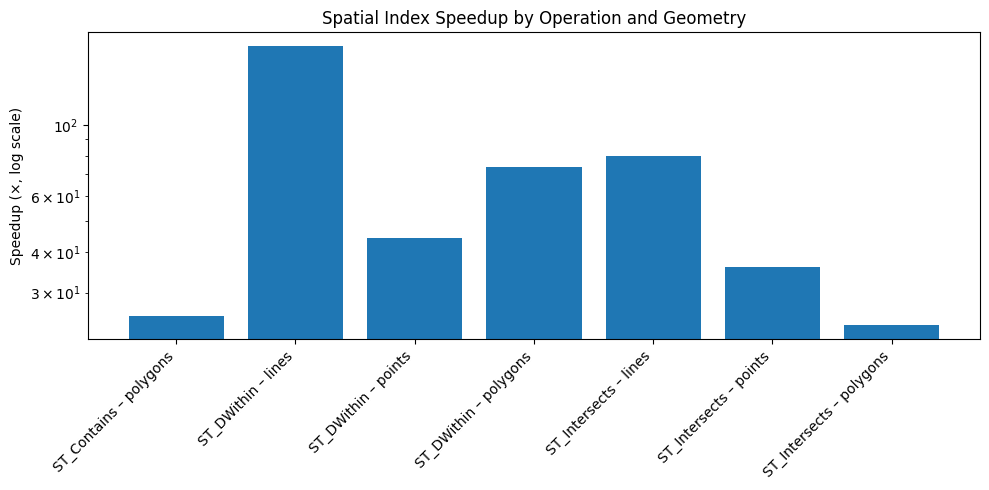

In [3]:



# Merge and compute speedup
df = pd.merge(agg_no, agg_ix, on=["operation", "geometry_type"])
df["speedup"] = df["no_index_ms"] / df["with_index_ms"]

# Label for plotting
df["label"] = df["operation"] + " – " + df["geometry_type"]

# Plot
plt.figure(figsize=(10, 5))
plt.bar(df["label"], df["speedup"])
plt.yscale("log")  # IMPORTANT
plt.ylabel("Speedup (×, log scale)")
plt.title("Spatial Index Speedup by Operation and Geometry")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
